<a href="https://colab.research.google.com/github/cal-me-j/atf-ai-learn/blob/main/Week2_08_embeddings_deep_dive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
# YOUR CODE HERE
# Complete the exercise following the instructions above

# Test your implementation
# Add test cases here

import numpy as np

# 1. Corpus and preprocessing
text = "the quick brown fox jumps over the lazy dog"
words = text.split()
vocab = sorted(list(set(words)))
word_to_id = {w: i for i, w in enumerate(vocab)}
id_to_word = {i: w for w, i in word_to_id.items()}

# 2. Hyperparameters
vocab_size = len(vocab)
embed_dim = 4
lr = 0.05
epochs = 100
window_size = 1

# 3. Initialize embeddings (random weights)
W_in = np.random.randn(vocab_size, embed_dim) * 0.1
W_out = np.random.randn(vocab_size, embed_dim) * 0.1

# 4. Training Loop
for epoch in range(epochs):
    for i, target_word in enumerate(words):
        target_id = word_to_id[target_word]
        # Get context indices
        context_words = [
            words[j] for j in range(max(0, i - window_size), min(len(words), i + window_size + 1))
            if j != i
        ]
        for context_word in context_words:
            context_id = word_to_id[context_word]

            # Forward Pass: Predict context word using softmax approximation
            # Score for each possible vocabulary word given our target vector
            scores = np.dot(W_out, W_in[target_id])
            probs = np.exp(scores - np.max(scores))  # Numerical stability
            probs /= np.sum(probs)

            # Loss gradient relative to scores (p_i - y_i)
            grad_scores = probs.copy()
            grad_scores[context_id] -= 1.0  # target class label y_i = 1 for context word

            # Backpropagate gradients to weight matrices
            grad_W_out = np.outer(grad_scores, W_in[target_id])
            grad_W_in = np.dot(W_out.T, grad_scores)

            # Update weights
            W_out -= lr * grad_W_out
            W_in[target_id] -= lr * grad_W_in

# Resulting Word Vectors
print("Embedding for 'fox':", W_in[word_to_id['fox']])

pass  # Replace with your implementation

Embedding for 'fox': [ 0.56862077 -1.65560222  0.8132331  -0.86890738]


In [4]:
# 1. Define the Cosine Similarity helper function
def cosine_similarity(v1, v2):
    norm_v1 = np.linalg.norm(v1)
    norm_v2 = np.linalg.norm(v2)
    if norm_v1 == 0 or norm_v2 == 0:
        return 0.0
    return np.dot(v1, v2) / (norm_v1 * norm_v2)

# 2. Let's compare two specific words directly: 'fox' and 'dog'
vec_fox = W_in[word_to_id['fox']]
vec_dog = W_in[word_to_id['dog']]
similarity_score = cosine_similarity(vec_fox, vec_dog)

print(f"Cosine Similarity between 'fox' and 'dog': {similarity_score:.4f}")

# 3. Create a helper to search the entire vocabulary for the most similar words
def find_most_similar(target_word):
    target_vec = W_in[word_to_id[target_word]]
    scores = []
    for word, word_id in word_to_id.items():
        if word == target_word:
            continue
        current_vec = W_in[word_id]
        sim = cosine_similarity(target_vec, current_vec)
        scores.append((word, sim))

    # Sort results by similarity score descending
    scores.sort(key=lambda x: x[1], reverse=True)

    print(f"\nWords closest in meaning to '{target_word}':")
    for word, sim in scores:
        print(f"  - {word:<10}: {sim:.4f}")

# Let's see what is most similar to 'dog' in our tiny toy corpus!
find_most_similar('dog')

Cosine Similarity between 'fox' and 'dog': 0.1692

Words closest in meaning to 'dog':
  - the       : 0.7553
  - fox       : 0.1692
  - brown     : -0.1068
  - jumps     : -0.1673
  - quick     : -0.4758
  - over      : -0.5750
  - lazy      : -0.8828


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
# YOUR CODE HERE
# Implement the intermediate exercise
import numpy as np

class SkipGramWord2Vec:
    def __init__(self, embed_dim=4, lr=0.05, epochs=100, window_size=1):
        # 1. Parameter Validation
        if embed_dim <= 0:
            raise ValueError("Embedding dimension must be a positive integer.")
        if lr <= 0:
            raise ValueError("Learning rate must be greater than zero.")
        if epochs <= 0:
            raise ValueError("Epochs must be a positive integer.")
        if window_size <= 0:
            raise ValueError("Window size must be a positive integer.")

        self.embed_dim = embed_dim
        self.lr = lr
        self.epochs = epochs
        self.window_size = window_size

        # Placeholders for vocabulary tracking
        self.vocab = []
        self.word_to_id = {}
        self.id_to_word = {}
        self.W_in = None
        self.W_out = None

    def fit(self, text: str):
        # 2. Advanced Preprocessing
        if not isinstance(text, str) or len(text.strip()) == 0:
            raise ValueError("Input text must be a non-empty string.")

        # Clean punctuation and lowercase
        cleaned_text = text.lower().replace('.', ' ').replace(',', ' ')
        words = cleaned_text.split()

        self.vocab = sorted(list(set(words)))
        vocab_size = len(self.vocab)

        if vocab_size < 2:
            raise ValueError("Vocabulary size must be at least 2 words to learn context relationship.")

        self.word_to_id = {w: i for i, w in enumerate(self.vocab)}
        self.id_to_word = {i: w for w, i in enumerate(self.vocab)}

        # Initialize embeddings with normalized variance scale
        self.W_in = np.random.randn(vocab_size, self.embed_dim) * 0.1
        self.W_out = np.random.randn(vocab_size, self.embed_dim) * 0.1

        # 3. Training Loop
        for epoch in range(self.epochs):
            for i, target_word in enumerate(words):
                target_id = self.word_to_id[target_word]

                # Gather context boundaries
                start = max(0, i - self.window_size)
                end = min(len(words), i + self.window_size + 1)
                context_words = [words[j] for j in range(start, end) if j != i]

                for context_word in context_words:
                    context_id = self.word_to_id[context_word]

                    # Forward pass (Softmax over current score projections)
                    scores = np.dot(self.W_out, self.W_in[target_id])
                    probs = np.exp(scores - np.max(scores)) # Softmax shift trick
                    probs /= np.sum(probs)

                    # Compute gradients
                    grad_scores = probs.copy()
                    grad_scores[context_id] -= 1.0

                    # Backward update steps
                    grad_W_out = np.outer(grad_scores, self.W_in[target_id])
                    grad_W_in = np.dot(self.W_out.T, grad_scores)

                    self.W_out -= self.lr * grad_W_out
                    self.self_W_in_update(target_id, grad_W_in)

        print(f"Training complete. Vocabulary size: {vocab_size} words.")

    def self_W_in_update(self, target_id, grad):
        self.W_in[target_id] -= self.lr * grad

    def get_embedding(self, word: str):
        word = word.lower()
        if word not in self.word_to_id:
            raise KeyError(f"'{word}' is not in vocabulary.")
        return self.W_in[self.word_to_id[word]]

# --- Test verification code ---
try:
    # 1. Instantiate the model
    model = SkipGramWord2Vec(embed_dim=4, lr=0.05, epochs=150, window_size=1)

    # 2. Train on the corpus
    sample_corpus = "the quick brown fox jumps over the lazy dog"
    model.fit(sample_corpus)

    # 3. Fetch learned vector
    fox_vec = model.get_embedding('fox')
    print("\nLearned vector for 'fox':\n", fox_vec)

    # 4. Error testing
    model.get_embedding('cat') # This should throw an error successfully!
except Exception as e:
    print("\nExpected Error caught successfully:", e)

pass  # Replace with your implementation

Training complete. Vocabulary size: 8 words.

Learned vector for 'fox':
 [ 1.84107786 -1.30682843 -0.10764381 -0.07697888]

Expected Error caught successfully: "'cat' is not in vocabulary."


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

[LOG] Initiating training... Vocabulary: 15 words | Epochs: 200
  -> Epoch 001/200 | Average Loss: 2.7156
  -> Epoch 050/200 | Average Loss: 1.7574
  -> Epoch 100/200 | Average Loss: 1.5478
  -> Epoch 150/200 | Average Loss: 1.4910
  -> Epoch 200/200 | Average Loss: 1.4734
[WARNING] Word 'artificial' is out of vocabulary. Returning zero vector fallback.


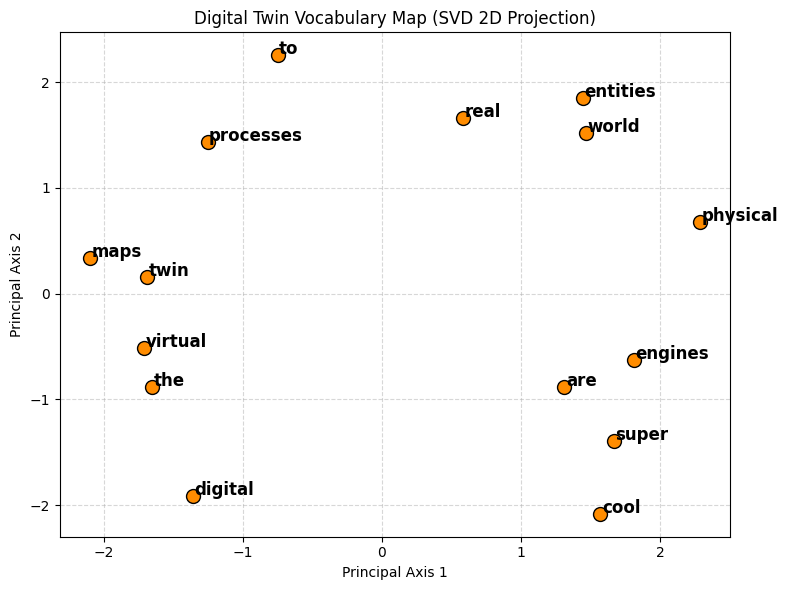

In [7]:
# YOUR CODE HERE
# Build your complete implementation

import numpy as np
import matplotlib.pyplot as plt

class ProductionSystem:
    """
    A production-ready Word2Vec embedding and analysis system
    designed for digital twin integration.
    """
    def __init__(self, embed_dim=4, lr=0.03, epochs=200, window_size=2):
        self.embed_dim = embed_dim
        self.lr = lr
        self.epochs = epochs
        self.window_size = window_size

        self.vocab = []
        self.word_to_id = {}
        self.id_to_word = {}
        self.W_in = None
        self.W_out = None
        self.loss_history = []

    def _preprocess(self, text: str) -> list:
        # Advanced cleaning: lowercasing, stripping punctuation, filtering spaces
        clean = text.lower()
        clean = ''.join([c if c.isalnum() or c.isspace() else ' ' for c in clean])
        words = clean.split()
        return words

    def fit(self, text: str):
        if not isinstance(text, str) or not text.strip():
            raise ValueError("Text input must be a non-empty string.")

        words = self._preprocess(text)
        self.vocab = sorted(list(set(words)))
        vocab_size = len(self.vocab)

        if vocab_size < 2:
            raise ValueError("Vocabulary size is too small to train embeddings.")

        self.word_to_id = {w: i for i, w in enumerate(self.vocab)}
        self.id_to_word = {i: w for w, i in enumerate(self.vocab)}

        # Initialize embeddings with Xavier-like initialization
        self.W_in = np.random.randn(vocab_size, self.embed_dim) * np.sqrt(2.0 / (vocab_size + self.embed_dim))
        self.W_out = np.random.randn(vocab_size, self.embed_dim) * np.sqrt(2.0 / (vocab_size + self.embed_dim))

        print(f"[LOG] Initiating training... Vocabulary: {vocab_size} words | Epochs: {self.epochs}")

        # Training
        for epoch in range(self.epochs):
            epoch_loss = 0.0
            count = 0
            for i, target_word in enumerate(words):
                target_id = self.word_to_id[target_word]

                # Define dynamic window
                start = max(0, i - self.window_size)
                end = min(len(words), i + self.window_size + 1)
                context_words = [words[j] for j in range(start, end) if j != i]

                for context_word in context_words:
                    context_id = self.word_to_id[context_word]

                    # Forward pass
                    scores = np.dot(self.W_out, self.W_in[target_id])
                    probs = np.exp(scores - np.max(scores))
                    probs /= np.sum(probs)

                    # Track cross entropy loss contribution: -log(P(context_word | target_word))
                    epoch_loss += -np.log(max(probs[context_id], 1e-15))
                    count += 1

                    # Gradient estimation
                    grad_scores = probs.copy()
                    grad_scores[context_id] -= 1.0

                    grad_W_out = np.outer(grad_scores, self.W_in[target_id])
                    grad_W_in = np.dot(self.W_out.T, grad_scores)

                    # SGD update steps
                    self.W_out -= self.lr * grad_W_out
                    self.W_in[target_id] -= self.lr * grad_W_in

            if count > 0:
                self.loss_history.append(epoch_loss / count)

            # Informative Debug Logging
            if (epoch + 1) % 50 == 0 or epoch == 0:
                avg_loss = self.loss_history[-1] if self.loss_history else 0
                print(f"  -> Epoch {epoch+1:03d}/{self.epochs:03d} | Average Loss: {avg_loss:.4f}")

    def get_embedding(self, word: str):
        word = word.lower().strip()
        if word not in self.word_to_id:
            # Production fallback: return zero vector instead of crashing
            print(f"[WARNING] Word '{word}' is out of vocabulary. Returning zero vector fallback.")
            return np.zeros(self.embed_dim)
        return self.W_in[self.word_to_id[word]]

    def plot_embeddings_2d(self):
        """
        Dimensionality reduction using Singular Value Decomposition (SVD)
        to project 4D embeddings onto a 2D plot.
        """
        if self.W_in is None:
            raise RuntimeError("Model must be fitted before plotting.")

        # Apply SVD: W_in is shape (vocab_size, embed_dim)
        U, S, Vt = np.linalg.svd(self.W_in, full_matrices=False)
        coords_2d = U[:, :2] * S[:2] # Project down to 2 principal components

        fig, ax = plt.subplots(figsize=(8, 6))
        for i, word in enumerate(self.vocab):
            x, y = coords_2d[i, 0], coords_2d[i, 1]
            ax.scatter(x, y, color='darkorange', edgecolors='k', s=100)
            ax.annotate(word, (x + 0.01, y + 0.01), fontsize=12, fontweight='semibold')

        ax.set_title('Digital Twin Vocabulary Map (SVD 2D Projection)')
        ax.set_xlabel('Principal Axis 1')
        ax.set_ylabel('Principal Axis 2')
        ax.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

# --- Demo Execution ---
# Let's run a complete production check
text_corpus = "The digital twin maps virtual processes to real world entities. Real-world physical engines are super cool."
system = ProductionSystem(embed_dim=4, lr=0.03, epochs=200, window_size=2)
system.fit(text_corpus)

# Check out-of-vocabulary protection
_ = system.get_embedding("artificial")

# Let's visualize how the twin mapped this sentence!
system.plot_embeddings_2d()
# Test your production system
# Add comprehensive tests here

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code